<a href="https://colab.research.google.com/github/jeevaprakash-S/24ADI006_24BAD048/blob/main/Experiment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Convolutional GAN (DCGAN) on MNIST


In [7]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: False


## PART A — Dataset preparation and image preprocessing

24BAD048 - Jeevaprakash S
Training images: 60000
Test images: 10000
Original image dimensions: (28, 28)
Training labels shape: (60000,)
Pixel range before normalization: 0 to 255


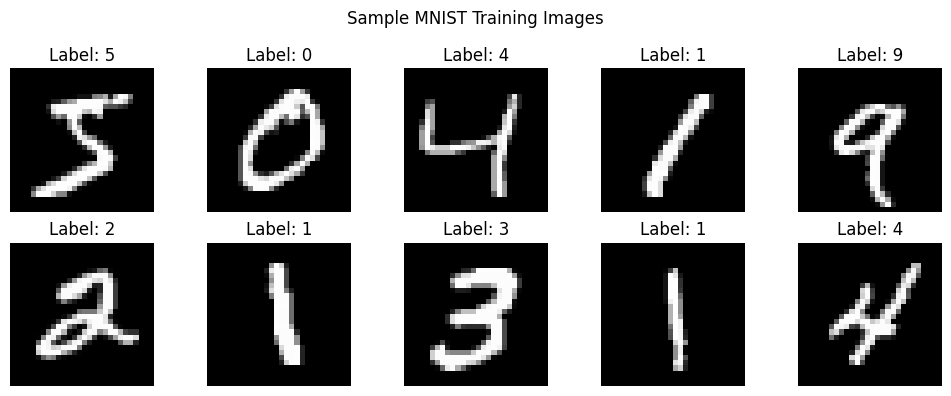

Processed training shape: (60000, 28, 28, 1)
Processed pixel range: -1.0 to 1.0
Batch size: 128
Batches per epoch: 468


In [8]:
print("24BAD048 - Jeevaprakash S")
# Load the MNIST handwritten digit dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape[0])
print("Test images:", x_test.shape[0])
print("Original image dimensions:", x_train.shape[1:])
print("Training labels shape:", y_train.shape)
print("Pixel range before normalization:", x_train.min(), "to", x_train.max())

# Display sample real images
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Sample MNIST Training Images")
plt.tight_layout()
plt.show()

# Normalize pixels from [0, 255] to [-1, 1]
# Add channel dimension: (N, 28, 28) -> (N, 28, 28, 1)
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

print("Processed training shape:", x_train.shape)
print("Processed pixel range:", float(x_train.min()), "to", float(x_train.max()))

# Prepare a shuffled, batched TensorFlow data pipeline
BATCH_SIZE = 128
BUFFER_SIZE = 60000
train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)
print("Batch size:", BATCH_SIZE)
print("Batches per epoch:", len(train_dataset))

## PART B — Implementing the Generator


24BAD048 - Jeevaprakash S


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

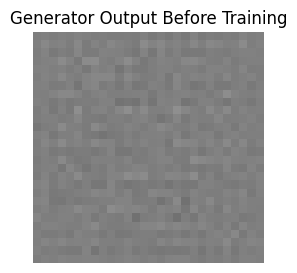

Generated image tensor shape: (1, 28, 28, 1)


In [9]:
print("24BAD048 - Jeevaprakash S")
LATENT_DIM = 100
IMAGE_SHAPE = (28, 28, 1)

def build_generator():
    model = keras.Sequential(name="Generator")
    model.add(layers.Input(shape=(LATENT_DIM,), name="noise_vector"))
    model.add(layers.Dense(7 * 7 * 128, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Reshape((7, 7, 128)))

    model.add(layers.Conv2DTranspose(64, kernel_size=4, strides=2,
                                     padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Conv2DTranspose(1, kernel_size=4, strides=2,
                                     padding="same", activation="tanh"))
    return model

generator = build_generator()
generator.summary()

# Generate one image before GAN training
noise = tf.random.normal([1, LATENT_DIM], seed=SEED)
generated_before_training = generator(noise, training=False)

plt.figure(figsize=(3, 3))
plt.imshow(generated_before_training[0, :, :, 0], cmap="gray", vmin=-1, vmax=1)
plt.title("Generator Output Before Training")
plt.axis("off")
plt.show()
print("Generated image tensor shape:", generated_before_training.shape)

## PART C — Implementing the Discriminator and GAN model


In [10]:
print("24BAD048 - Jeevaprakash S")
def build_discriminator():
    model = keras.Sequential(name="Discriminator")
    model.add(layers.Input(shape=IMAGE_SHAPE))
    model.add(layers.Conv2D(64, kernel_size=4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, kernel_size=4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))
    model.add(layers.Flatten())
    model.add(layers.Dense(1, activation="sigmoid"))
    return model

discriminator = build_discriminator()
discriminator.summary()

# Compile discriminator with binary cross-entropy and Adam optimizer
discriminator_optimizer = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator.compile(
    optimizer=discriminator_optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Build combined GAN. Freeze discriminator weights for the Generator update.
discriminator.trainable = False
noise_input = keras.Input(shape=(LATENT_DIM,), name="gan_noise")
generated_image = generator(noise_input)
gan_output = discriminator(generated_image)
gan = keras.Model(noise_input, gan_output, name="GAN")
gan.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)

print("\nGenerator summary:")
generator.summary()
print("\nDiscriminator summary:")
discriminator.summary()
print("\nCombined GAN summary:")
gan.summary()

# Re-enable discriminator training for its own training step.
discriminator.trainable = True

24BAD048 - Jeevaprakash S


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

...

Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gan_noise (InputLayer)          │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       784,641 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 923,202 (3.52 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 151,233 (590.75 KB)

## PART D — GAN training and synthetic image generation

Epoch 01/10 | D loss: 0.7256 | G loss: 0.4964 | Time: 502.1s


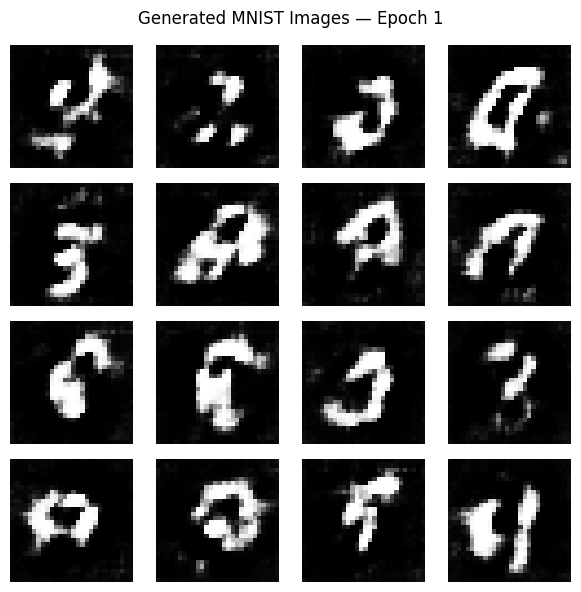

Saved: gan_mnist_outputs/generated_epoch_001.png
Epoch 02/10 | D loss: 0.7839 | G loss: 0.4712 | Time: 432.7s


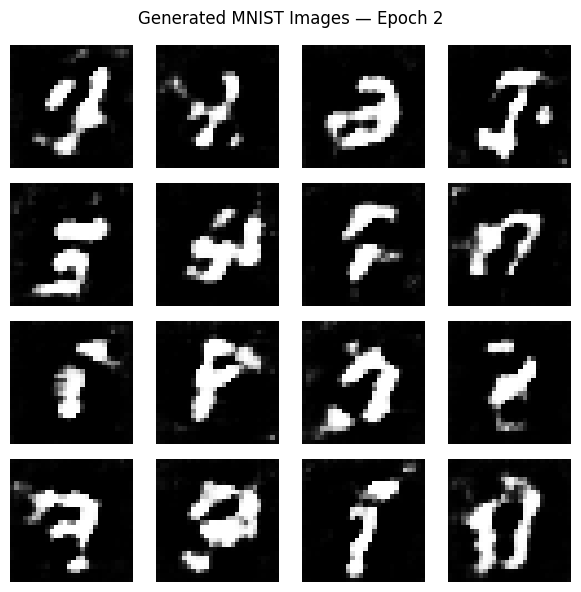

Saved: gan_mnist_outputs/generated_epoch_002.png
Epoch 03/10 | D loss: 0.8008 | G loss: 0.4756 | Time: 426.1s
Epoch 04/10 | D loss: 0.8106 | G loss: 0.4779 | Time: 441.9s


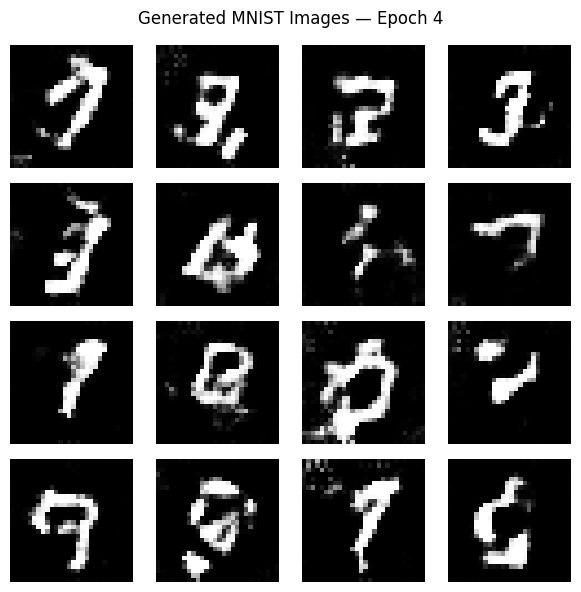

Saved: gan_mnist_outputs/generated_epoch_004.png
Epoch 05/10 | D loss: 0.8178 | G loss: 0.4783 | Time: 424.1s
Epoch 06/10 | D loss: 0.8250 | G loss: 0.4788 | Time: 427.8s


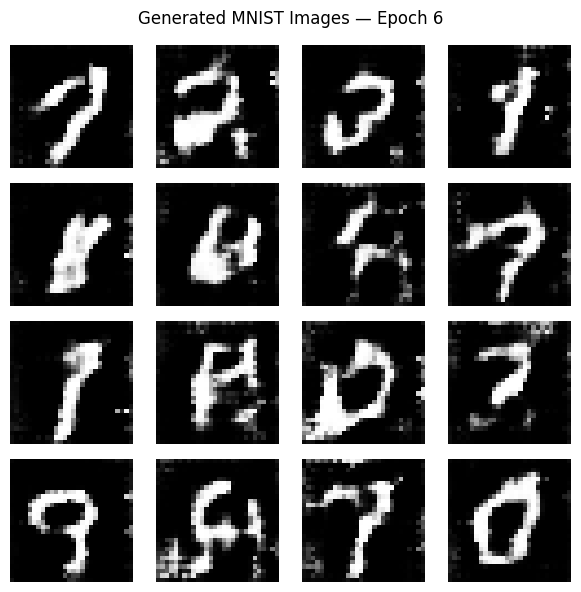

Saved: gan_mnist_outputs/generated_epoch_006.png
Epoch 07/10 | D loss: 0.8358 | G loss: 0.4822 | Time: 427.5s
Epoch 08/10 | D loss: 0.8489 | G loss: 0.4865 | Time: 424.3s


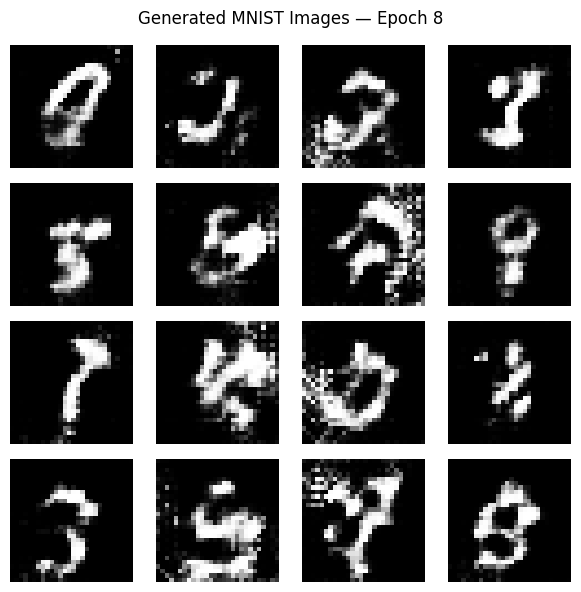

Saved: gan_mnist_outputs/generated_epoch_008.png
Epoch 09/10 | D loss: 0.8740 | G loss: 0.5020 | Time: 423.6s
Epoch 10/10 | D loss: 0.9034 | G loss: 0.5244 | Time: 441.9s


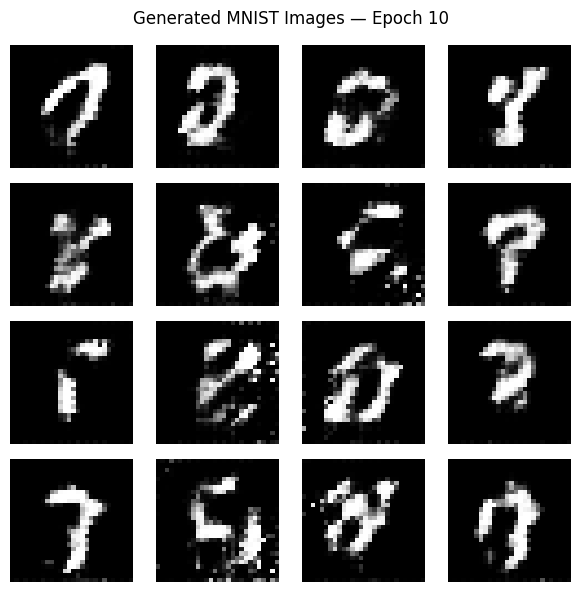

Saved: gan_mnist_outputs/generated_epoch_010.png
Training complete.


In [11]:
# Training configuration
EPOCHS = 10  # Increase (e.g., 20–50) for better results if time/resources allow
NUM_EXAMPLES_TO_GENERATE = 16
SAMPLE_SEED = tf.random.normal([NUM_EXAMPLES_TO_GENERATE, LATENT_DIM], seed=SEED)

generator_losses = []
discriminator_losses = []
epoch_history = []
OUTPUT_DIR = "gan_mnist_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_generated_grid(epoch, predictions, show=True):
    predictions = predictions.numpy()
    fig, axes = plt.subplots(4, 4, figsize=(6, 6))
    for i, ax in enumerate(axes.flat):
        ax.imshow(predictions[i, :, :, 0], cmap="gray", vmin=-1, vmax=1)
        ax.axis("off")
    fig.suptitle(f"Generated MNIST Images — Epoch {epoch}")
    plt.tight_layout()
    filepath = os.path.join(OUTPUT_DIR, f"generated_epoch_{epoch:03d}.png")
    plt.savefig(filepath, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    print("Saved:", filepath)

# Custom alternating training loop
for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    d_epoch_losses = []
    g_epoch_losses = []

    for real_images in train_dataset:
        batch_size = tf.shape(real_images)[0]

        # 1. Train Discriminator on real images (label 1) and fake images (label 0)
        noise = tf.random.normal([batch_size, LATENT_DIM])
        fake_images = generator(noise, training=True)

        real_labels = tf.ones((batch_size, 1)) * 0.9  # mild label smoothing
        fake_labels = tf.zeros((batch_size, 1))

        d_loss_real = discriminator.train_on_batch(real_images, real_labels)
        d_loss_fake = discriminator.train_on_batch(fake_images, fake_labels)
        d_loss = 0.5 * (float(d_loss_real[0]) + float(d_loss_fake[0]))
        d_epoch_losses.append(d_loss)

        # 2. Train Generator through combined GAN, aiming for "real" labels
        noise = tf.random.normal([batch_size, LATENT_DIM])
        misleading_labels = tf.ones((batch_size, 1))
        g_loss = gan.train_on_batch(noise, misleading_labels)
        g_loss_value = float(np.asarray(g_loss).reshape(-1)[0])
        g_epoch_losses.append(g_loss_value)


    mean_d_loss = float(np.mean(d_epoch_losses))
    mean_g_loss = float(np.mean(g_epoch_losses))
    discriminator_losses.append(mean_d_loss)
    generator_losses.append(mean_g_loss)
    epoch_history.append(epoch)

    elapsed = time.time() - start_time
    print(f"Epoch {epoch:02d}/{EPOCHS} | D loss: {mean_d_loss:.4f} | "
          f"G loss: {mean_g_loss:.4f} | Time: {elapsed:.1f}s")

    # Show and save generated images at regular intervals and at final epoch
    if epoch == 1 or epoch % 2 == 0 or epoch == EPOCHS:
        samples = generator(SAMPLE_SEED, training=False)
        save_generated_grid(epoch, samples, show=True)

print("Training complete.")

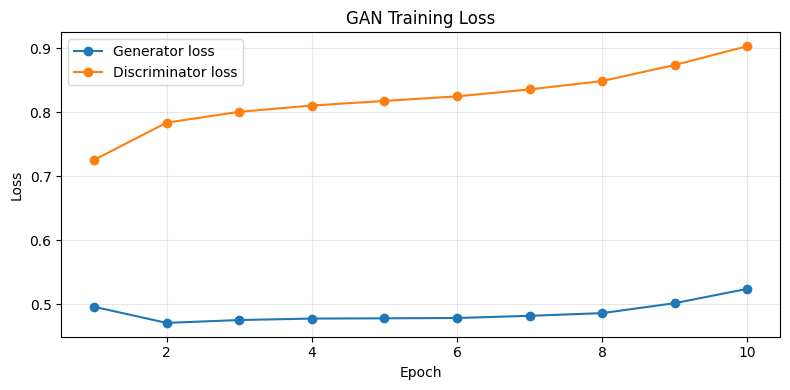

Saved loss plot: gan_mnist_outputs/training_losses.png


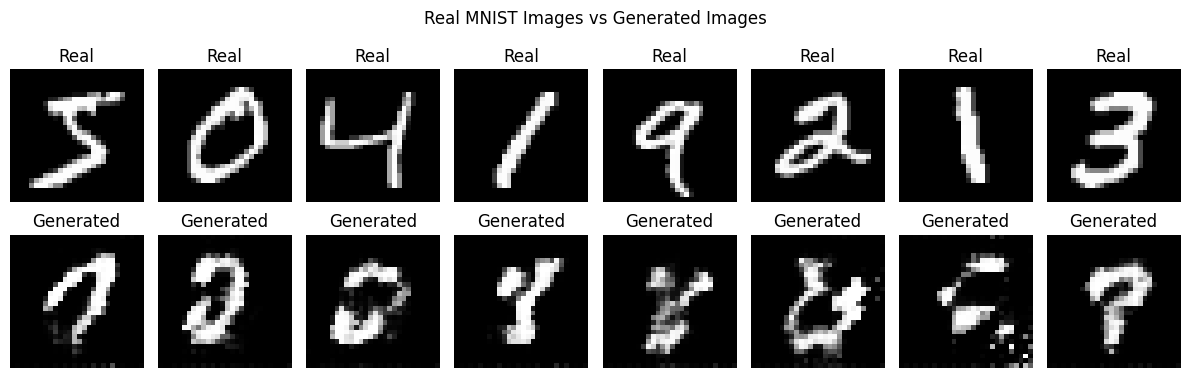

Saved comparison: gan_mnist_outputs/real_vs_generated.png


In [12]:
# Plot Generator and Discriminator loss curves
plt.figure(figsize=(8, 4))
plt.plot(epoch_history, generator_losses, marker="o", label="Generator loss")
plt.plot(epoch_history, discriminator_losses, marker="o", label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
loss_plot_path = os.path.join(OUTPUT_DIR, "training_losses.png")
plt.savefig(loss_plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved loss plot:", loss_plot_path)

# Compare real images with final generated images
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(x_train[i, :, :, 0], cmap="gray", vmin=-1, vmax=1)
    axes[0, i].set_title("Real")
    axes[0, i].axis("off")

final_samples = generator(SAMPLE_SEED, training=False).numpy()
for i in range(8):
    axes[1, i].imshow(final_samples[i, :, :, 0], cmap="gray", vmin=-1, vmax=1)
    axes[1, i].set_title("Generated")
    axes[1, i].axis("off")

plt.suptitle("Real MNIST Images vs Generated Images")
plt.tight_layout()
comparison_path = os.path.join(OUTPUT_DIR, "real_vs_generated.png")
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved comparison:", comparison_path)

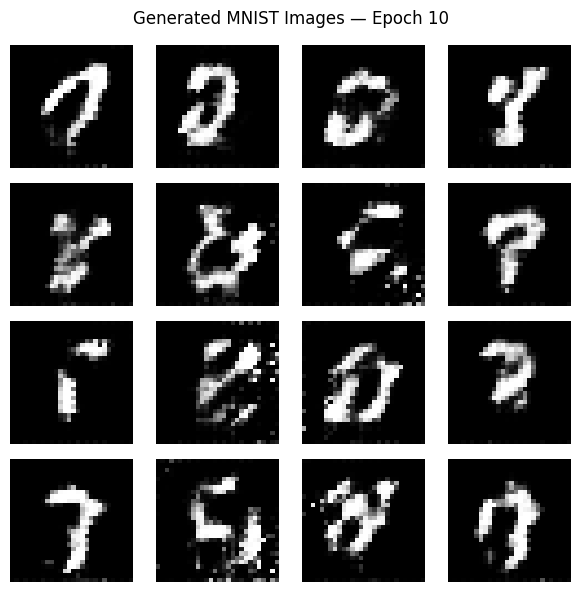

Saved: gan_mnist_outputs/generated_epoch_010.png
All output images and loss plots are saved in: /content/gan_mnist_outputs
ZIP archive: /content/gan_mnist_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# Save final generated images individually and as a grid
final_images = generator(SAMPLE_SEED, training=False).numpy()
for i, image in enumerate(final_images):
    plt.imsave(
        os.path.join(OUTPUT_DIR, f"final_generated_{i+1:02d}.png"),
        image[:, :, 0],
        cmap="gray",
        vmin=-1,
        vmax=1
    )

save_generated_grid(EPOCHS, tf.convert_to_tensor(final_images), show=True)

# Download all output images as a ZIP when running in Google Colab.
import shutil
zip_path = shutil.make_archive("gan_mnist_outputs", "zip", OUTPUT_DIR)
print("All output images and loss plots are saved in:", os.path.abspath(OUTPUT_DIR))
print("ZIP archive:", os.path.abspath(zip_path))

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Google Colab; find the ZIP in the current working directory.")